In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import json
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = "/content/drive/MyDrive/Traffic_Sign_Project"
DATASET_DIR = "/content/traffic_sign_dataset/traffic_sign"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR = os.path.join(DATASET_DIR, "test")

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("TensorFlow:", tf.__version__)
print("Training directory:", TRAIN_DIR)
print("Test directory:", TEST_DIR)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Training directory: /content/traffic_sign_dataset/traffic_sign/train
Test directory: /content/traffic_sign_dataset/traffic_sign/test
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/Traffic_Sign_Project/traffic_sign.zip"
EXTRACT_ROOT = "/content/traffic_sign_dataset"

assert os.path.exists(ZIP_PATH), f"ZIP not found: {ZIP_PATH}"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_ROOT)

# Locate the actual train and test folders
for root, dirs, files in os.walk(EXTRACT_ROOT):
    if "train" in dirs and "test" in dirs:
        TRAIN_DIR = os.path.join(root, "train")
        TEST_DIR = os.path.join(root, "test")
        break
else:
    raise FileNotFoundError(
        "Could not find train and test folders after extraction."
    )

print("Train folder exists:", os.path.exists(TRAIN_DIR))
print("Test folder exists:", os.path.exists(TEST_DIR))
print("Train class folders:", len(os.listdir(TRAIN_DIR)))
print("Test class folders:", len(os.listdir(TEST_DIR)))
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR:", TEST_DIR)

Train folder exists: True
Test folder exists: True
Train class folders: 85
Test class folders: 85
TRAIN_DIR: /content/traffic_sign_dataset/traffic_sign/train
TEST_DIR: /content/traffic_sign_dataset/traffic_sign/test


In [ ]:
from pathlib import Path

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

train_classes = sorted(
    p.name for p in Path(TRAIN_DIR).iterdir() if p.is_dir()
)
test_classes = sorted(
    p.name for p in Path(TEST_DIR).iterdir() if p.is_dir()
)

train_count = sum(
    1 for p in Path(TRAIN_DIR).rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)
test_count = sum(
    1 for p in Path(TEST_DIR).rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

print("Training images:", train_count)
print("Test images:", test_count)
print("Training classes:", len(train_classes))
print("Test classes:", len(test_classes))
print("Same class names:", train_classes == test_classes)

assert len(train_classes) == 85, "Expected 85 training classes"
assert train_classes == test_classes, "Class folders do not match"

Training images: 4438
Test images: 1288
Training classes: 85
Test classes: 85
Same class names: True


In [ ]:
from pathlib import Path
import random
import shutil

TRAIN_DIR = Path(TRAIN_DIR)
VALIDATION_DIR = Path("/content/traffic_sign_dataset/validation")

print("Training folder exists:", TRAIN_DIR.exists())
print("Training class folders:", len([
    p for p in TRAIN_DIR.iterdir() if p.is_dir()
]))

# Recreate an empty validation folder
if VALIDATION_DIR.exists():
    shutil.rmtree(VALIDATION_DIR)

VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

print("Validation folder ready:", VALIDATION_DIR.exists())

Training folder exists: True
Training class folders: 85
Validation folder ready: True


In [ ]:
import random
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
random.seed(42)

train_counts = {}
val_counts = {}

for class_folder in sorted(TRAIN_DIR.iterdir()):
    if not class_folder.is_dir():
        continue

    images = [
        p for p in class_folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]

    if len(images) < 2:
        print(f"Skipping split: {class_folder.name} has fewer than 2 images.")
        continue

    random.shuffle(images)

    val_count = min(
        max(1, round(len(images) * 0.20)),
        len(images) - 1
    )

    val_class_dir = VALIDATION_DIR / class_folder.name
    val_class_dir.mkdir(parents=True, exist_ok=True)

    for image_path in images[:val_count]:
        shutil.copy2(image_path, val_class_dir / image_path.name)

    train_counts[class_folder.name] = len(images) - val_count
    val_counts[class_folder.name] = val_count

train_classes = {
    p.name for p in TRAIN_DIR.iterdir() if p.is_dir()
}
val_classes = {
    p.name for p in VALIDATION_DIR.iterdir() if p.is_dir()
}

print("\nTraining classes:", len(train_classes))
print("Validation classes:", len(val_classes))
print("Training images retained:", sum(train_counts.values()))
print("Validation images:", sum(val_counts.values()))
print("Missing validation classes:", sorted(train_classes - val_classes))

assert train_classes == val_classes, "Some classes are missing from validation!"
assert len(train_classes) == 85

print("SUCCESS: All 85 classes are present in both folders.")


Training classes: 85
Validation classes: 85
Training images retained: 3551
Validation images: 887
Missing validation classes: []
SUCCESS: All 85 classes are present in both folders.


In [ ]:
from pathlib import Path
import shutil

SOURCE_TRAIN_DIR = Path(
    "/content/drive/MyDrive/Traffic_Sign_Project"
)  # Project folder; original dataset remains untouched

ORIGINAL_TRAIN_DIR = Path(TRAIN_DIR)
VALIDATION_DIR = Path("/content/traffic_sign_dataset/validation")
RESNET_TRAIN_DIR = Path("/content/traffic_sign_dataset/resnet_train")

if RESNET_TRAIN_DIR.exists():
    shutil.rmtree(RESNET_TRAIN_DIR)

RESNET_TRAIN_DIR.mkdir(parents=True)

for class_dir in sorted(ORIGINAL_TRAIN_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    val_class_dir = VALIDATION_DIR / class_dir.name
    output_class_dir = RESNET_TRAIN_DIR / class_dir.name
    output_class_dir.mkdir(parents=True)

    validation_names = {p.name for p in val_class_dir.iterdir() if p.is_file()}

    for image_path in class_dir.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTS:
            if image_path.name not in validation_names:
                shutil.copy2(image_path, output_class_dir / image_path.name)

def count_images(folder):
    return sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )

print("Clean training images:", count_images(RESNET_TRAIN_DIR))
print("Validation images:", count_images(VALIDATION_DIR))
print("Training classes:", len([p for p in RESNET_TRAIN_DIR.iterdir() if p.is_dir()]))

Clean training images: 3551
Validation images: 887
Training classes: 85


In [ ]:
import tensorflow as tf

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    str(RESNET_TRAIN_DIR),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    str(VALIDATION_DIR),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    str(TEST_DIR),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

CLASS_NAMES = train_ds.class_names

assert CLASS_NAMES == val_ds.class_names == test_ds.class_names

print("\nNumber of classes:", len(CLASS_NAMES))
print("First 10 classes:", CLASS_NAMES[:10])
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 3551 files belonging to 85 classes.
Found 887 files belonging to 85 classes.
Found 1288 files belonging to 85 classes.

Number of classes: 85
First 10 classes: ['ALL_MOTOR_VEHICLE_PROHIBITED', 'AXLE_LOAD_LIMIT', 'BARRIER_AHEAD', 'BULLOCK_AND_HANDCART_PROHIBITED', 'BULLOCK_PROHIBITED', 'CATTLE', 'COMPULSARY_AHEAD', 'COMPULSARY_AHEAD_OR_TURN_LEFT', 'COMPULSARY_AHEAD_OR_TURN_RIGHT', 'COMPULSARY_CYCLE_TRACK']
Training batches: 111
Validation batches: 28
Test batches: 41


# ResNet18

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def residual_block(x, filters, stride=1):
    shortcut = x

    # First convolution
    x = layers.Conv2D(
        filters, kernel_size=3, strides=stride,
        padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Second convolution
    x = layers.Conv2D(
        filters, kernel_size=3, strides=1,
        padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)

    # Match shortcut dimensions when needed
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, kernel_size=1, strides=stride,
            padding="same", use_bias=False
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    # Residual connection
    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)

    return x


def build_resnet18(input_shape=(224, 224, 3), num_classes=85):
    inputs = keras.Input(shape=input_shape)

    # Initial convolution
    x = layers.Conv2D(
        64, kernel_size=7, strides=2,
        padding="same", use_bias=False
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(
        pool_size=3, strides=2, padding="same"
    )(x)

    # Four residual stages: two blocks per stage
    for filters, first_stride in [(64, 1), (128, 2), (256, 2), (512, 2)]:
        x = residual_block(x, filters, stride=first_stride)
        x = residual_block(x, filters, stride=1)

    # Classification head
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return keras.Model(inputs, outputs, name="ResNet18")


resnet18 = build_resnet18(num_classes=len(CLASS_NAMES))
resnet18.summary()

Model: "ResNet18"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │      9,408 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 56, 56,    │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 56, 56,    │     36,864 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │     36,864 │ re_lu_1[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 56, 56,    │          0 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 56, 56,    │     36,864 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     36,864 │ re_lu_3[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_4[0][0]  

 Total params: 11,229,717 (42.84 MB)

 Trainable params: 11,220,117 (42.80 MB)

 Non-trainable params: 9,600 (37.50 KB)

In [ ]:
resnet18.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("ResNet18 compiled successfully!")
print("Output classes:", resnet18.output_shape[-1])
print("Total parameters:", f"{resnet18.count_params():,}")

ResNet18 compiled successfully!
Output classes: 85
Total parameters: 11,229,717


In [ ]:
import os
from tensorflow import keras

MODEL_DIR = "/content/drive/MyDrive/Traffic_Sign_Project/models"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(MODEL_DIR, "resnet18_best.keras")

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

print("Callbacks ready.")
print("Best model will be saved to:", BEST_MODEL_PATH)

Callbacks ready.
Best model will be saved to: /content/drive/MyDrive/Traffic_Sign_Project/models/resnet18_best.keras


In [ ]:
EPOCHS = 50

history = resnet18.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - accuracy: 0.1579 - loss: 3.6938
Epoch 1: val_loss improved from None to 119.44615, saving model to /content/drive/MyDrive/Traffic_Sign_Project/models/resnet18_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Traffic_Sign_Project/models/resnet18_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 84s 514ms/step - accuracy: 0.2005 - loss: 3.2188 - val_accuracy: 0.0406 - val_loss: 119.4462 - learning_rate: 0.0010
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step - accuracy: 0.2726 - loss: 2.6471
Epoch 2: val_loss improved from 119.44615 to 26.82902, saving model to /content/drive/MyDrive/Traffic_Sign_Project/models/resnet18_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Traffic_Sign_Project/models/resnet18_best.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 39s 350ms/step - accuracy: 0.2861 - loss: 2.6069 - val_accuracy: 0.0462 - val_loss: 26.8290 - learning_rate: 0.0010
Epoch 3/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0

40 min

In [ ]:
import os
import tensorflow as tf

BEST_MODEL_PATH = (
    "/content/drive/MyDrive/Traffic_Sign_Project/"
    "models/resnet18_best.keras"
)

assert os.path.exists(BEST_MODEL_PATH), "Saved model not found!"

resnet18 = tf.keras.models.load_model(BEST_MODEL_PATH)

print("Best ResNet18 model loaded successfully!")
print("Model output:", resnet18.output_shape)

Best ResNet18 model loaded successfully!
Model output: (None, 85)


In [ ]:
test_loss, test_accuracy = resnet18.evaluate(test_ds, verbose=1)

print("\nResNet18 Test Results")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 11s 153ms/step - accuracy: 0.8758 - loss: 0.5710

ResNet18 Test Results
Test Loss: 0.5710
Test Accuracy: 87.58%


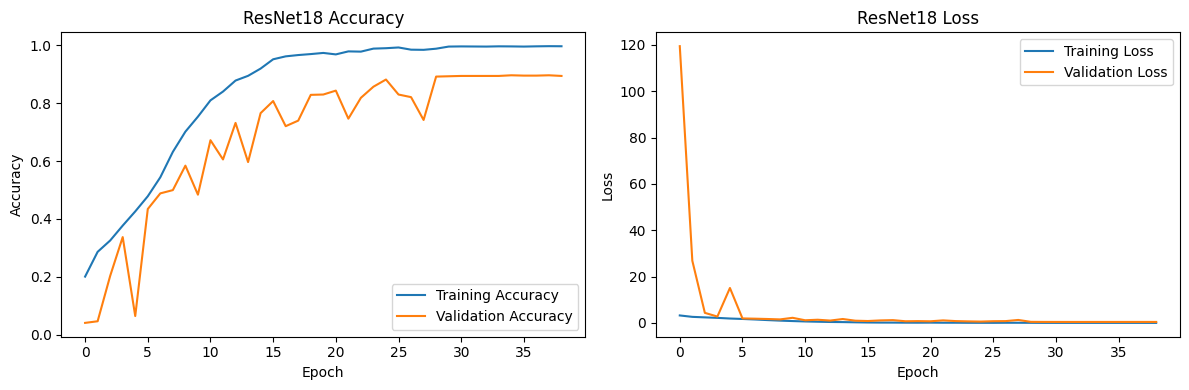

Epochs completed: 39
Best epoch: 33
Best validation accuracy: 0.8963
Lowest validation loss: 0.4117


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ResNet18 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ResNet18 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

best_epoch = min(
    range(len(history.history["val_loss"])),
    key=lambda i: history.history["val_loss"][i]
) + 1

print("Epochs completed:", len(history.history["loss"]))
print("Best epoch:", best_epoch)
print(f"Best validation accuracy: {max(history.history['val_accuracy']):.4f}")
print(f"Lowest validation loss: {min(history.history['val_loss']):.4f}")

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import matplotlib.pyplot as plt

MODEL_PATH = (
    "/content/drive/MyDrive/Traffic_Sign_Project/"
    "models/resnet18_best.keras"
)

resnet18 = tf.keras.models.load_model(MODEL_PATH)

# Evaluate test loss and accuracy
test_loss, test_accuracy = resnet18.evaluate(test_ds, verbose=1)

# True labels and predictions
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_prob = resnet18.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Metrics
print("\n===== RESNET18 TEST EVALUATION =====")
print(f"Test Loss:          {test_loss:.4f}")
print(f"Test Accuracy:      {accuracy_score(y_true, y_pred) * 100:.2f}%")
print(f"Macro Precision:    {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:       {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro F1-score:     {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted Precision: {precision_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Weighted Recall:    {recall_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Weighted F1-score:  {f1_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0,
    digits=3
))

41/41 ━━━━━━━━━━━━━━━━━━━━ 12s 157ms/step - accuracy: 0.8758 - loss: 0.5710
41/41 ━━━━━━━━━━━━━━━━━━━━ 7s 133ms/step

===== RESNET18 TEST EVALUATION =====
Test Loss:          0.5710
Test Accuracy:      87.58%
Macro Precision:    0.7427
Macro Recall:       0.7284
Macro F1-score:     0.7225
Weighted Precision: 0.8859
Weighted Recall:    0.8758
Weighted F1-score:  0.8733

===== CLASSIFICATION REPORT =====
                                 precision    recall  f1-score   support

   ALL_MOTOR_VEHICLE_PROHIBITED      0.333     0.200     0.250         5
                AXLE_LOAD_LIMIT      1.000     1.000     1.000         5
                  BARRIER_AHEAD      0.000     0.000     0.000         2
BULLOCK_AND_HANDCART_PROHIBITED      0.500     0.500     0.500         2
             BULLOCK_PROHIBITED      0.750     0.600     0.667         5
                         CATTLE      0.636     0.636     0.636        11
               COMPULSARY_AHEAD      0.714     1.000     0.833        10
  COMPULS

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np

# Get true labels and predictions
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = resnet18.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Print metrics
print("2. ResNet18")
print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Macro Precision: {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro Recall: {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro F1-score: {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted F1-score: {f1_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")

41/41 ━━━━━━━━━━━━━━━━━━━━ 7s 132ms/step
2. ResNet18
Accuracy: 0.8758
Macro Precision: 0.7427
Macro Recall: 0.7284
Macro F1-score: 0.7225
Weighted F1-score: 0.8733


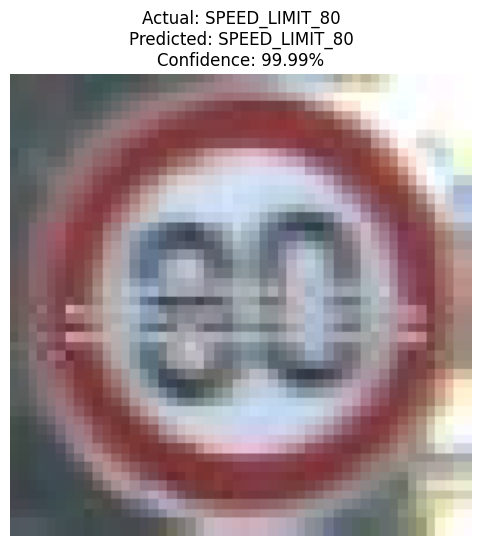

Image: 70220.jpg
Actual class: SPEED_LIMIT_80
Predicted class: SPEED_LIMIT_80
Confidence: 99.99%
Correct prediction: True

Top 3 predictions:
SPEED_LIMIT_80: 99.99%
SPEED_LIMIT_50: 0.00%
HEIGHT_LIMIT: 0.00%


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path

# Load the best saved ResNet18 model
MODEL_PATH = (
    "/content/drive/MyDrive/Traffic_Sign_Project/"
    "models/resnet18_best.keras"
)

resnet18 = tf.keras.models.load_model(MODEL_PATH)

# Select a random image from the test dataset
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = [
    p for p in Path(TEST_DIR).rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]

image_path = np.random.choice(image_paths)

# Load image
img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

img_array = tf.keras.utils.img_to_array(img)
img_batch = np.expand_dims(img_array, axis=0)

# Predict
probabilities = resnet18.predict(img_batch, verbose=0)[0]

predicted_idx = int(np.argmax(probabilities))
predicted_class = CLASS_NAMES[predicted_idx]
confidence = float(probabilities[predicted_idx]) * 100

actual_class = image_path.parent.name

# Display image and prediction
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Actual: {actual_class}\n"
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Image:", image_path.name)
print("Actual class:", actual_class)
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")
print("Correct prediction:", actual_class == predicted_class)

# Top 3 predictions
print("\nTop 3 predictions:")

for idx in np.argsort(probabilities)[-3:][::-1]:
    print(f"{CLASS_NAMES[idx]}: {probabilities[idx] * 100:.2f}%")

In [ ]:
import os
import json
import tensorflow as tf

from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/Traffic_Sign_Project"
MODEL_DIR = os.path.join(PROJECT_DIR, "models", "resnet18")
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(MODEL_DIR, "resnet18_best.keras")
CLASS_PATH = os.path.join(MODEL_DIR, "class_names.json")

# Load the best checkpoint saved during training
resnet18 = tf.keras.models.load_model(
    os.path.join(PROJECT_DIR, "models", "resnet18_best.keras")
)

# Save model and class names together in the new folder
resnet18.save(MODEL_PATH)

with open(CLASS_PATH, "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, indent=4, ensure_ascii=False)

print("Model saved:", os.path.exists(MODEL_PATH))
print("Class names saved:", os.path.exists(CLASS_PATH))
print("Number of classes:", len(CLASS_NAMES))
print("Model path:", MODEL_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved: True
Class names saved: True
Number of classes: 85
Model path: /content/drive/MyDrive/Traffic_Sign_Project/models/resnet18/resnet18_best.keras
